# 第三章多维特征的客户细分代码

# 3.1客户细分数据说明

数据读取

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_columns",7)  # 为方便截图设置最大显示列数为7
bank = pd.read_csv('data_clust.csv',skipinitialspace=True)
bank.describe(include='all')

,interested_travel,computer_owner,age,...,HH_has_children,HH_adults_num,interested_reading
count,149788.000000,149788.000000,167177.000000,...,159899,145906.000000,167177
unique,NaN,NaN,NaN,...,2,NaN,5
top,NaN,NaN,NaN,...,N,NaN,3
freq,NaN,NaN,NaN,...,111462,NaN,65096
mean,0.427745,0.856571,59.507079,...,NaN,2.770832,NaN
std,0.494753,0.350511,14.311733,...,NaN,1.285417,NaN
min,0.000000,0.000000,18.000000,...,NaN,0.000000,NaN
25%,0.000000,1.000000,49.000000,...,NaN,2.000000,NaN
50%,0.000000,1.000000,59.000000,...,NaN,2.000000,NaN
75%,1.000000,1.000000,70.000000,...,NaN,4.000000,NaN


# 3.2 预处理

3.2.1 填补缺失值

In [2]:
for col in bank.columns:
    if bank[col].hasnans:
        print(col)

interested_travel
computer_owner
HH_has_children
HH_adults_num


这四个有缺失值的字段中，interested_travel、computer_owner、HH_adults_num这三个字段是数值型分类变量，而且缺失比例并不大，因此用它们各自的众数进行填补

In [3]:
fill_cols = ['interested_travel', 'computer_owner', 'HH_adults_num']
fill_values = {col: bank[col].mode()[0] for col in fill_cols}
bank = bank.fillna(fill_values)

3.2.2 修订错误值

In [4]:
import numpy as np

bank['HH_has_children'] = bank['HH_has_children']\
    .replace({'N': 0, 'Y': 1, np.nan: 0})\
    .infer_objects(copy=False)

C:\Users\15587\AppData\Local\Temp\ipykernel_19296\1861798196.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({'N': 0, 'Y': 1, np.nan: 0})\


In [5]:
bank['interested_reading'] = bank['interested_reading']\
    .replace({'.':'0'}).astype('int')

3.2.3 处理离散型变量

In [6]:
from itertools import combinations
from scipy import stats
_cols = [
    'interested_travel',
    'computer_owner',
    'marital',
    'interested_golf', 
    'interested_gambling', 
    'HH_has_children',
    'interested_reading'
]
sample = bank[_cols].sample(3000, random_state=12345)

# 对离散变量两两进行卡方检验
for colA, colB in combinations(_cols, 2):
    crosstab = pd.crosstab(sample[colA], sample[colB])
    pval = stats.chi2_contingency(crosstab)[1]

In [7]:
# 设定置信度阈值为0.05
if pval > 0.05:
        print('p-value = %0.3f between "%s" and "%s"' %(pval, colA, colB))


In [8]:
#对interested_reading进行二值化
from sklearn.preprocessing import Binarizer
binarizer = Binarizer(threshold=1.5)
bank['interested_reading'] = binarizer.fit_transform(
    bank[['interested_reading']])

# 生成偏好填充率
interest =[
    'interested_travel',
    'computer_owner',
    'interested_golf', 
    'interested_gambling',
    'interested_reading'
]
n_ = len(interest)

bank = bank.drop(interest, axis=1)\
               .assign(interest=bank[interest].sum(axis=1) / n_)
bank.head()

,age,home_value,loan_ratio,...,HH_has_children,HH_adults_num,interest
0,64,124035,73,...,0.0,2.0,0.2
1,69,138574,73,...,0.0,5.0,0.4
2,57,148136,77,...,0.0,2.0,0.2
3,80,162532,74,...,1.0,2.0,1.0
4,48,133580,77,...,1.0,3.0,0.8


3.2.4 正态化与标准化

In [9]:
continuous_cols = ['age', 'home_value', 'risk_score', 'interested_sport', 
                   'HH_dieting', 'auto_member', 'HH_grandparent',
                   'HH_head_age', 'loan_ratio']

categorical_cols = ['marital', 'interest', 'HH_adults_num']

discreate_cols = ['HH_has_children'] # 不进入聚类模型

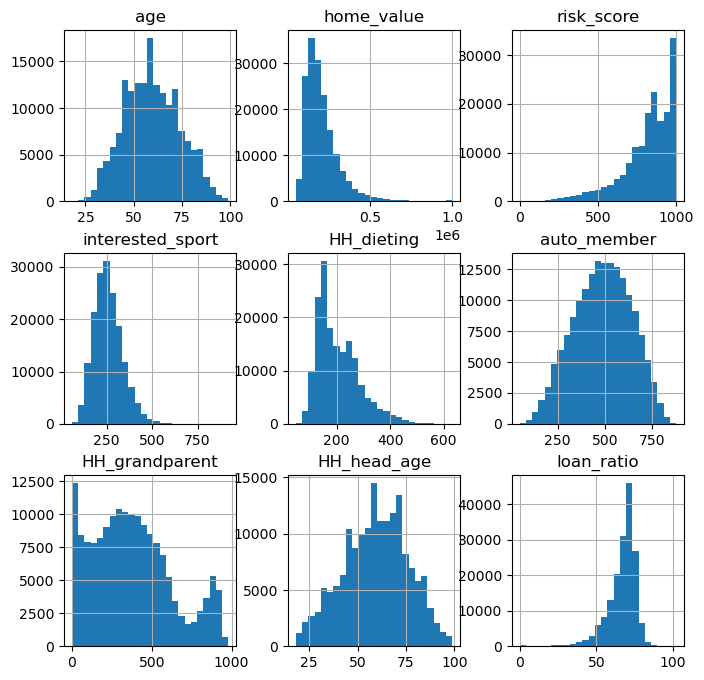

In [10]:
bank[continuous_cols].hist(bins=25,figsize=[8, 8])
plt.show()

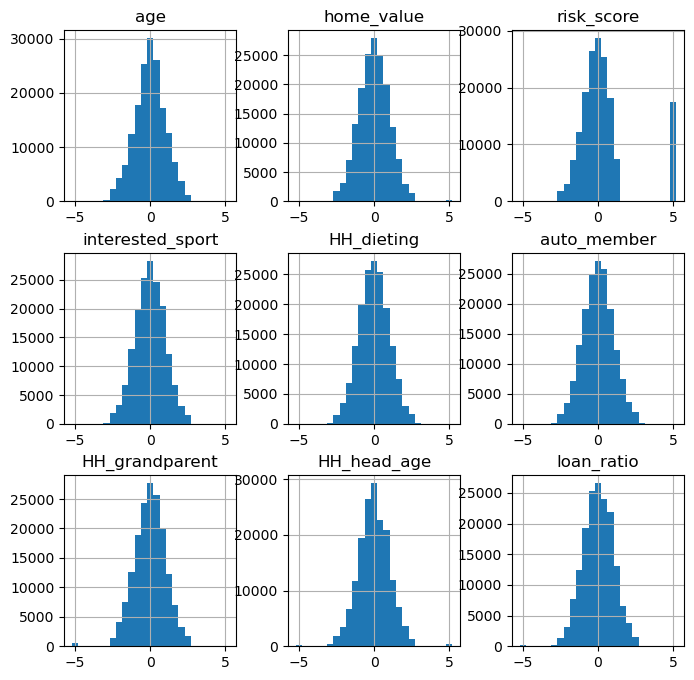

In [11]:
from sklearn.preprocessing import QuantileTransformer

qt = QuantileTransformer(n_quantiles=100, output_distribution='normal')
qt_data = qt.fit_transform(bank[continuous_cols])

pd.DataFrame(qt_data,columns=continuous_cols).hist(bins=25, figsize=[8,8])
plt.show()

In [12]:
from sklearn.preprocessing import scale

scale_data = scale(bank[categorical_cols])
# 合并数据
data = np.hstack([qt_data, scale_data, bank[discreate_cols]])
data = pd.DataFrame(
    data, columns=continuous_cols + categorical_cols + discreate_cols)
data.head()

,age,home_value,risk_score,...,interest,HH_adults_num,HH_has_children
0,0.308666,-0.886132,0.589456,...,-1.035281,-0.547836,0.0
1,0.619855,-0.624763,5.199338,...,-0.354828,1.895118,0.0
2,-0.126937,-0.470890,-0.925985,...,-1.035281,-0.547836,0.0
3,1.335178,-0.250167,0.589456,...,1.686529,-0.547836,1.0
4,-0.764710,-0.707695,1.144237,...,1.006077,0.266482,1.0


# 3.3 维度分析

In [13]:
# 根据业务解释，将变量划分为大的维度 `household`, `hobby`
from sklearn.decomposition import PCA
household = ['age', 'marital', 'HH_adults_num', 'home_value', 
             'risk_score', 'HH_grandparent', 'HH_head_age', 'loan_ratio']
hobby = ['HH_dieting', 'auto_member','interest', 'interested_sport']

#  确定`household`维度中主成分解释的方差比率
pca_hh = PCA().fit(data[household])
pca_hh.explained_variance_ratio_.cumsum()

array([0.35217342, 0.56484702, 0.73006644, 0.82918287, 0.88325615,
       0.92773707, 0.96608508, 1.        ])

In [14]:
from sklearn import preprocessing
data_household = preprocessing.scale(data[household])
data_hobby = preprocessing.scale(data[hobby])

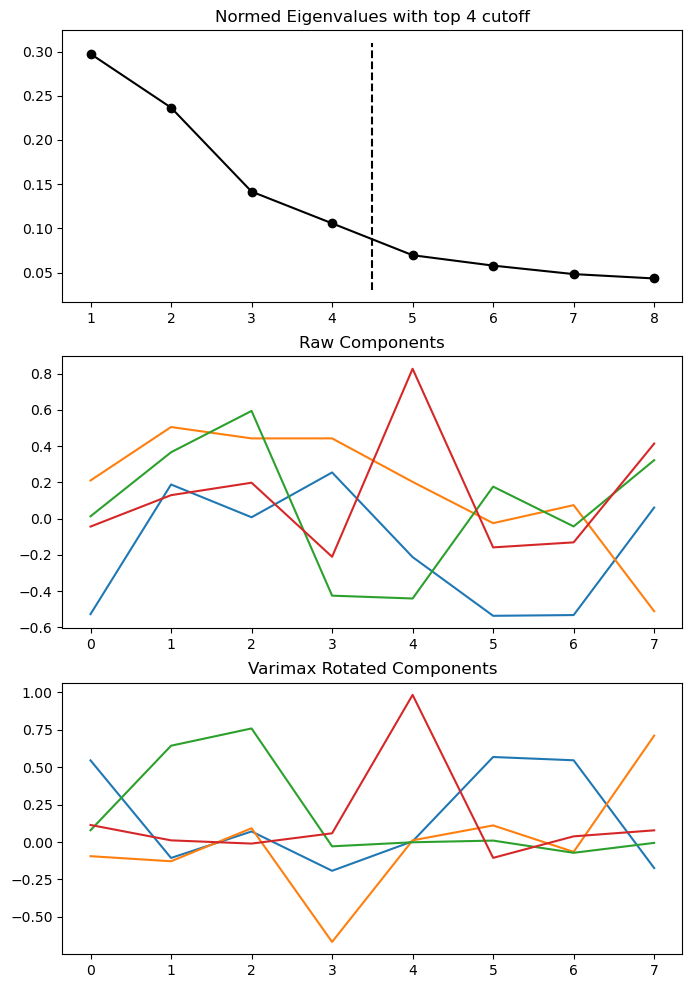

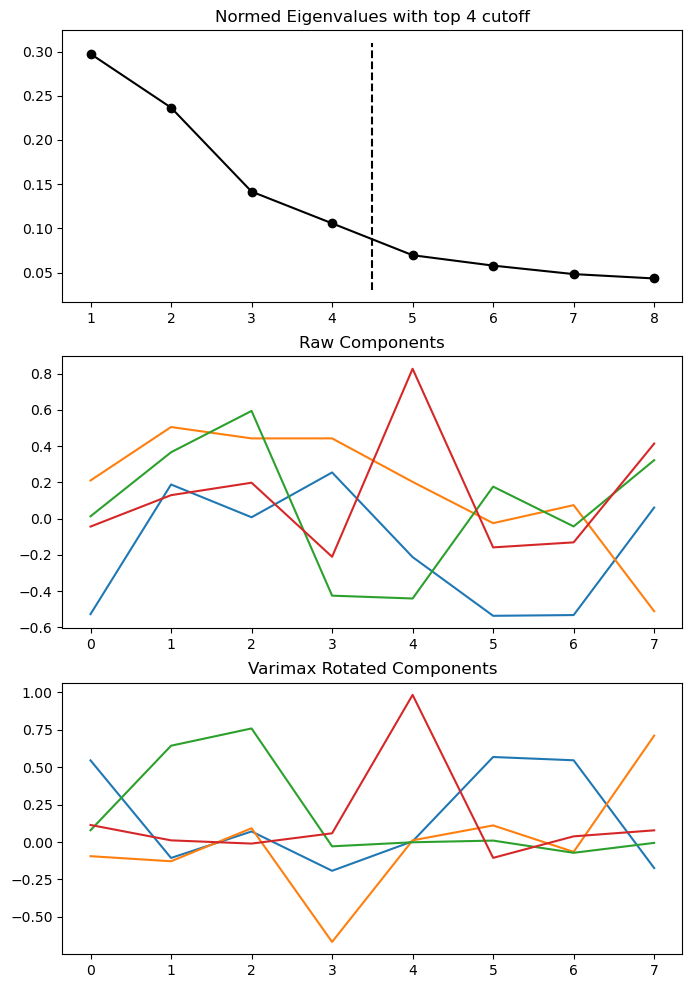

In [15]:
from fa_kit import FactorAnalysis
from fa_kit import plotting as fa_plotting
fa_hh = FactorAnalysis.load_data_samples(
    data_household,
    preproc_demean=True,
    preproc_scale=True
)
fa_hh.extract_components()

# 使用“top_n”法保留4个因子
fa_hh.find_comps_to_retain(method='top_n',num_keep=4)

# 最大方差旋转
fa_hh.rotate_components(method='varimax')
fa_plotting.graph_summary(fa_hh)

In [16]:
pd.DataFrame(fa_hh.comps['rot'].T, columns=household)

,age,marital,HH_adults_num,...,HH_grandparent,HH_head_age,loan_ratio
0,0.544834,-0.106587,0.070284,...,0.567373,0.545530,-0.174073
1,-0.094871,-0.128758,0.091457,...,0.110560,-0.066093,0.709944
2,0.078514,0.642702,0.758007,...,0.009258,-0.072285,-0.006039
3,0.113516,0.010830,-0.010705,...,-0.106048,0.037619,0.077762


对客户的“偏好属性”进行因子分析（保留3个因子）

In [17]:
fa_hb = FactorAnalysis.load_data_samples(
    data_hobby, 
    preproc_demean=True,
    preproc_scale=True
)
fa_hb.extract_components()
fa_hb.find_comps_to_retain(method='top_n', num_keep=3)
fa_hb.rotate_components(method='varimax')
pd.DataFrame(fa_hb.comps['rot'].T, columns=hobby)

,HH_dieting,auto_member,interest,interested_sport
0,-0.175213,0.867894,0.033299,0.463629
1,0.832748,-0.121159,0.027833,0.539516
2,0.087998,0.071201,0.978863,-0.170334


根据业务解释为每个因子赋予一个名字，得到的因子得分将作为聚类模型的输入

In [18]:
# 计算household因子得分
data_hh = pd.DataFrame(
    np.dot(data[household], fa_hh.comps['rot']), 
    columns=['life_circle','finance', 'HH_size', 'risk']
)

# 计算hobby因子得分
data_hb = pd.DataFrame(
    np.dot(data[hobby], fa_hb.comps['rot']), 
    columns=['sports', 'health', 'leisure']
)

# 3.4聚类

In [19]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def cluster_plot(data, k_range=range(2, 12), n_init=5, sample_size=2000
                ):
    scores = []  # 保存模型效果的评分
    models = {}  # 保存模型

    # 遍历选择的所有k
    for k in k_range:
        kmeans = KMeans(n_clusters=k, n_init=n_init) # 初始化模型
        kmeans.fit(data)  # 训练
        models[k] = kmeans
        sil = silhouette_score(data, kmeans.labels_, 
                               sample_size=sample_size)
        scores.append([k, kmeans.inertia_, sil]) # inertia_即SSD 

    scores_df = pd.DataFrame(scores, columns=['k','sum_square_dist', 'sil'])

    #  绘制簇内离差平方和图
    plt.figure(figsize=[9, 2])
    plt.subplot(121, ylabel='sum_square')
    plt.plot(scores_df.k, scores_df.sum_square_dist)
   
#  绘制轮廓系数图
    plt.subplot(122, ylabel='silhouette_score')
    plt.plot(scores_df.k, scores_df.sil)
    plt.show()

    return models  # 返回不同k值对应的模型

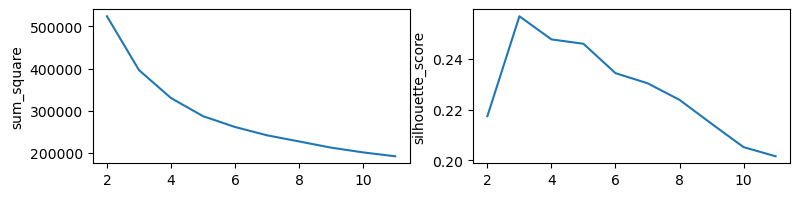

--------------------------------------------------------------------------------


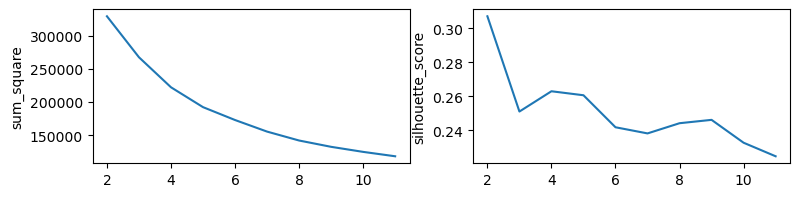

In [20]:
# 对因子得分进行标准化
from sklearn.preprocessing import StandardScaler
hh_scaler = StandardScaler()
scale_data_hh = hh_scaler.fit_transform(data_hh)
hb_scaler = StandardScaler()
scale_data_hb = hb_scaler.fit_transform(data_hb)

# 绘制簇内离差平方和、轮廓系数图
models_hh = cluster_plot(scale_data_hh)
print("-" * 80)
models_hb = cluster_plot(scale_data_hb)

In [21]:
hh_labels = pd.DataFrame(models_hh[3].labels_, columns=['hh'])
hb_labels = pd.DataFrame(models_hb[2].labels_, columns=['hb'])
clusters = bank.join(hh_labels).join(hb_labels)
clusters.head()

,age,home_value,loan_ratio,...,interest,hh,hb
0,64,124035,73,...,0.2,1,1
1,69,138574,73,...,0.4,2,0
2,57,148136,77,...,0.2,1,1
3,80,162532,74,...,1.0,1,0
4,48,133580,77,...,0.8,1,1


# 3.5 簇特征的解释

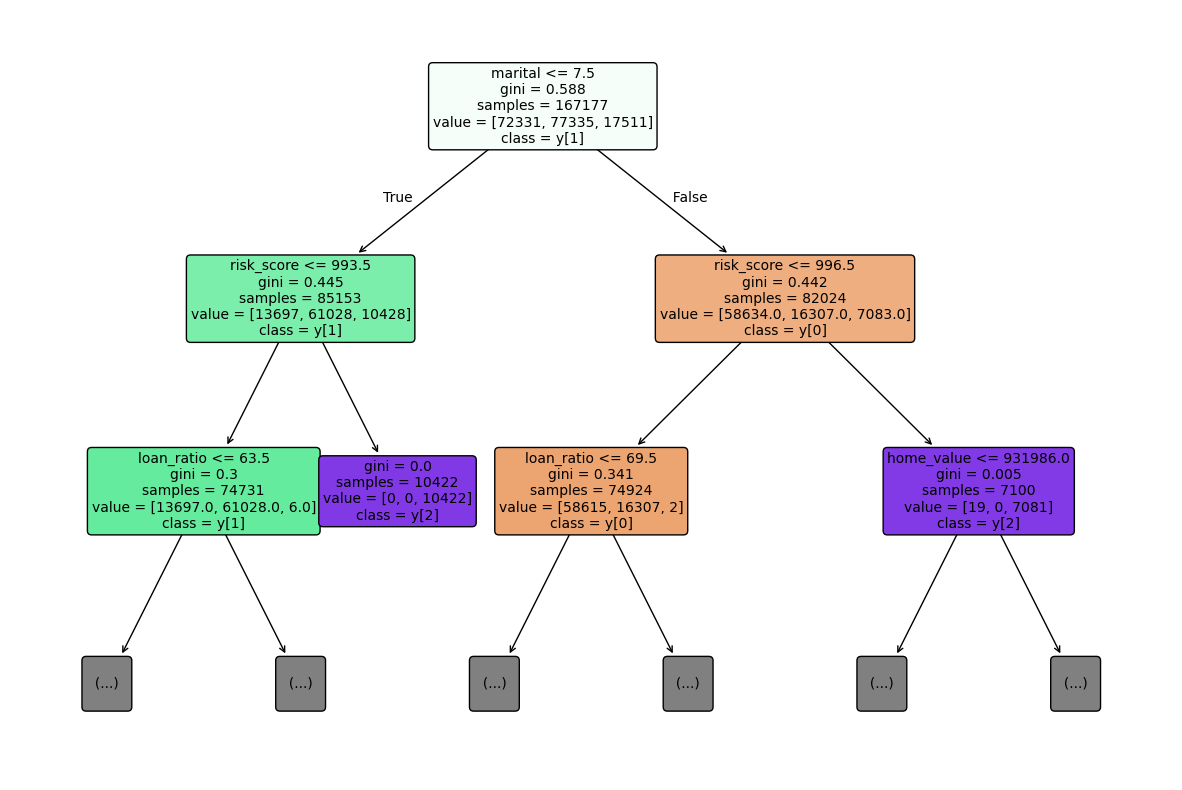

In [24]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, DecisionTreeClassifier

tree_hh = DecisionTreeClassifier()
tree_hh.fit(clusters[household], clusters['hh']) 

# 设置画布大小
plt.figure(figsize=(15, 10))

# 绘制决策树
plot_tree(
    tree_hh, 
    feature_names=household, 
    class_names=True, 
    max_depth=2, 
    filled=True,  # 为节点填充颜色，更美观
    rounded=True, # 圆角节点
    fontsize=10
)

plt.show()

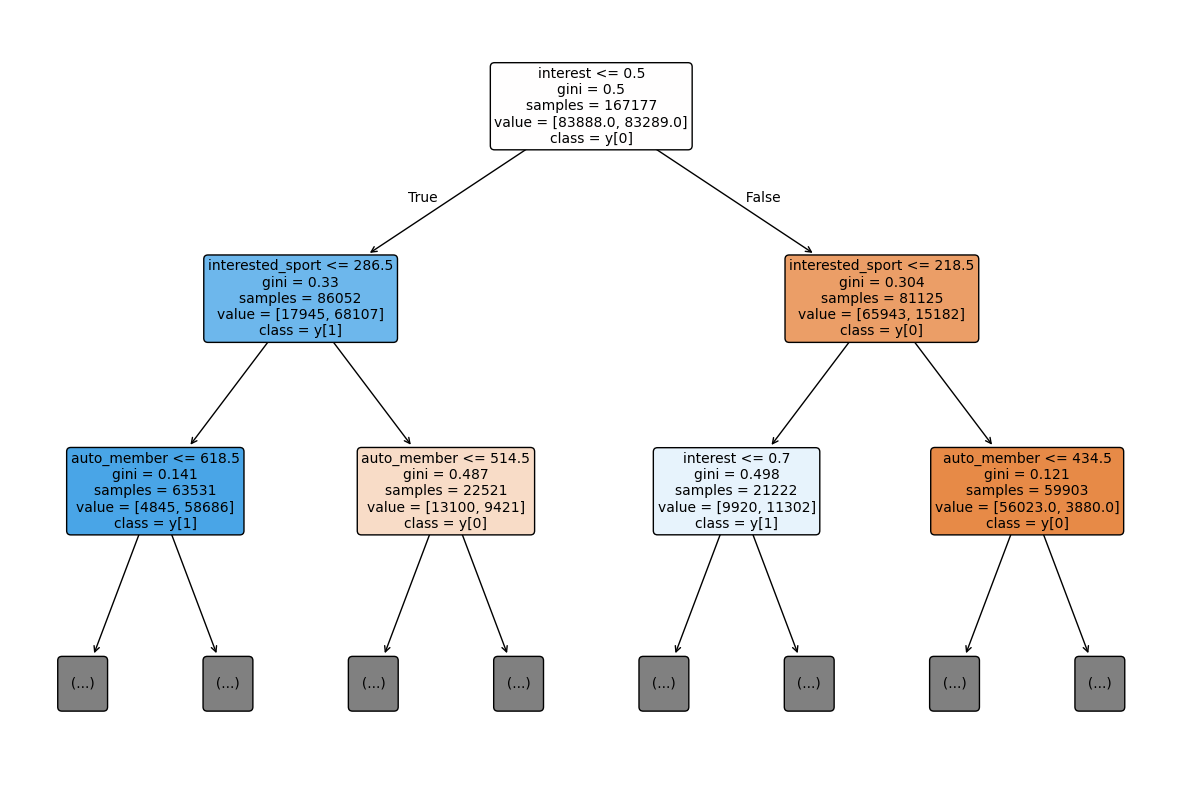

In [28]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree_hb = DecisionTreeClassifier()
tree_hb.fit(clusters[hobby], clusters['hb'])

plt.figure(figsize=(15, 10))
plot_tree(
    tree_hb,
    feature_names=hobby,
    class_names=True,
    max_depth=2,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()

In [26]:
cluster_pt = pd.pivot_table(clusters, index='hh', columns='hb',
                            aggfunc='mean').T
cluster_pt.swaplevel('hb', 0).sort_index(level=0)

hh                               0              1              2
hb                                                              
0  HH_adults_num          3.345917       2.183894       2.771755
   HH_dieting           229.396957     257.495544     227.723304
   HH_grandparent       333.949134     534.230148     514.434424
   HH_has_children        0.368213       0.172205       0.165883
   HH_head_age           57.848343      63.674893      67.496594
   age                   60.558713      64.143486      70.391442
   auto_member          594.081949     525.740015     596.709393
   home_value        276985.006536  164098.920085  210127.141610
   interest               0.679964       0.720114       0.693274
   interested_sport     301.820801     292.664971     318.669193
   loan_ratio            60.217102      70.490529      63.404010
   marital                8.612027       5.611466       6.868848
   risk_score           845.435691     798.521449     999.983978
1  HH_adults_num          3.273257       2.018380       2.422686
   HH_dieting           167.077418     174.002499     158.466422
   HH_grandparent       271.587895     353.440425     399.902511
   HH_has_children        0.456495       0.239933       0.148138
   HH_head_age           54.769138      57.765851      68.845090
   age                   55.983260      54.612016      66.066309
   auto_member          454.113606     366.304768     448.010158
   home_value        237078.885942  156257.424362  175517.013685
   interest               0.349810       0.294974       0.293256
   interested_sport     227.642027     209.431214     238.018905
   loan_ratio            65.194824      72.021625      68.437923
   marital                8.682203       5.183663       5.888403
   risk_score           813.711658     738.394030     999.991676